In [3]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/lingululwanishine/playground-series-s4e4/sample_submission.csv
/kaggle/input/datasets/lingululwanishine/playground-series-s4e4/test.csv
/kaggle/input/datasets/lingululwanishine/playground-series-s4e4/train.csv


Train shape: (90615, 10)
Test shape: (60411, 9)
Sample submission shape: (60411, 2)

Predictors: ['Length', 'Diameter', 'Height', 'Whole weight', 'Whole weight.1', 'Whole weight.2', 'Shell weight', 'Sex_I', 'Sex_M']
Missing predictor values: 0

Lasso best alpha: 0.0001
Features retained for subset search: ['Length', 'Diameter', 'Height', 'Whole weight', 'Whole weight.1', 'Whole weight.2', 'Shell weight', 'Sex_I', 'Sex_M']
Lasso CV RMSLE: 0.16404

Best subset: ['Length', 'Diameter', 'Height', 'Whole weight', 'Whole weight.1', 'Whole weight.2', 'Shell weight', 'Sex_I']
Best-subset CV RMSLE: 0.16403
Best-subset holdout RMSLE: 0.16662

PCR selected components: 9
PCR CV RMSLE: 0.16403
PCR holdout RMSLE: 0.16662

Holdout comparison:
Lasso-screened best subset: RMSLE = 0.16662
PCR: RMSLE = 0.16662
Selected for submission: Lasso-screened best subset

Best-subset coefficients (standardized predictors):
Whole weight.1   -0.2493
Shell weight      0.1878
Diameter          0.1016
Whole weight      

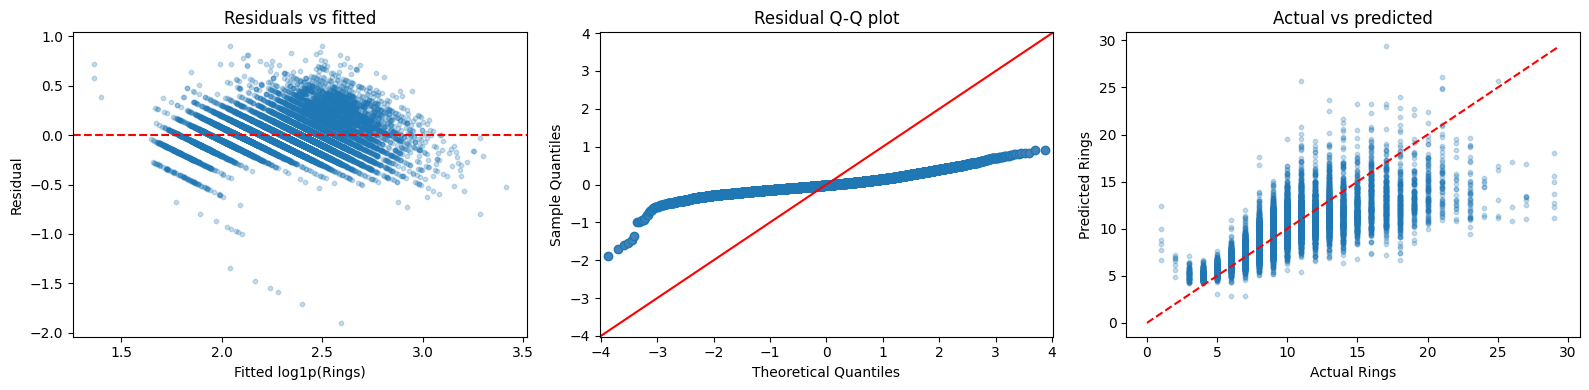


Saved submission: /kaggle/working/submission.csv
      id      Rings
0  90615   8.842756
1  90616   9.977505
2  90617  10.056433
3  90618  11.034846
4  90619   7.552617
Submission shape: (60411, 2)
Missing predictions: 0
Negative predictions: 0


In [4]:
# If needed, uncomment:
# %pip install pandas numpy scikit-learn scipy statsmodels matplotlib
 
from pathlib import Path
from itertools import combinations
 
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
 
from scipy.stats import shapiro
from sklearn.decomposition import PCA
from sklearn.linear_model import Lasso, LinearRegression
from sklearn.metrics import mean_squared_log_error, make_scorer
from sklearn.model_selection import GridSearchCV, KFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from statsmodels.stats.diagnostic import het_breuschpagan
 
 
# ---------------------------------------------------------------------
# Load the three competition input files
# ---------------------------------------------------------------------
DATA_DIR = Path(
    "/kaggle/input/datasets/lingululwanishine/playground-series-s4e4"
)
OUTPUT_DIR = Path("/kaggle/working")
 
train = pd.read_csv(DATA_DIR / "train.csv")
test = pd.read_csv(DATA_DIR / "test.csv")
sample_submission = pd.read_csv(DATA_DIR / "sample_submission.csv")
 
ID = "id"
TARGET = "Rings"
SEED = 42
 
assert TARGET in train.columns, f"Target column {TARGET!r} not found."
assert ID in train.columns and ID in test.columns
assert list(sample_submission.columns) == [ID, TARGET], (
    f"Unexpected sample submission columns: {sample_submission.columns.tolist()}"
)
assert np.array_equal(
    test[ID].to_numpy(),
    sample_submission[ID].to_numpy()
), "Test IDs and sample-submission IDs do not match in order."
 
print("Train shape:", train.shape)
print("Test shape:", test.shape)
print("Sample submission shape:", sample_submission.shape)
 
 
# ---------------------------------------------------------------------
# Prepare predictors and target
# ---------------------------------------------------------------------
y = train[TARGET].astype(float)
y_log = np.log1p(y)
 
# Encode train and test together so they have identical predictor columns.
combined_features = pd.concat(
    [
        train.drop(columns=[TARGET, ID]),
        test.drop(columns=[ID]),
    ],
    ignore_index=True,
)
 
combined_features = pd.get_dummies(
    combined_features,
    drop_first=True,
    dtype=float,
)
 
X = combined_features.iloc[:len(train)].reset_index(drop=True)
X_test = combined_features.iloc[len(train):].reset_index(drop=True)
feature_names = X.columns.tolist()
 
if X.isna().any().any() or X_test.isna().any().any():
    raise ValueError("Missing predictor values found; impute them before fitting.")
 
print("\nPredictors:", feature_names)
print("Missing predictor values:", int(X.isna().sum().sum()))
 
 
# ---------------------------------------------------------------------
# Metric and holdout split
# ---------------------------------------------------------------------
def rmsle_from_log(y_true_log, y_pred_log):
    """Calculate RMSLE from true and predicted log1p(target) values."""
    actual = np.maximum(0, np.expm1(np.asarray(y_true_log)))
    predicted = np.maximum(0, np.expm1(np.asarray(y_pred_log)))
    return np.sqrt(mean_squared_log_error(actual, predicted))
 
 
RMSLE_SCORER = make_scorer(
    rmsle_from_log,
    greater_is_better=False,
)
 
all_indices = np.arange(len(X))
fit_indices, holdout_indices = train_test_split(
    all_indices,
    test_size=0.20,
    random_state=SEED,
)
 
X_fit = X.iloc[fit_indices]
X_holdout = X.iloc[holdout_indices]
y_fit_log = y_log.iloc[fit_indices]
y_holdout_log = y_log.iloc[holdout_indices]
 
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)
 
 
# ---------------------------------------------------------------------
# Model 1: Lasso screening followed by best-subset selection
# ---------------------------------------------------------------------
lasso_pipeline = Pipeline(
    [
        ("scale", StandardScaler()),
        ("lasso", Lasso(max_iter=50_000, random_state=SEED)),
    ]
)
 
lasso_search = GridSearchCV(
    estimator=lasso_pipeline,
    param_grid={"lasso__alpha": np.logspace(-4, 0.5, 30)},
    scoring=RMSLE_SCORER,
    cv=cv,
    n_jobs=-1,
)
lasso_search.fit(X_fit, y_fit_log)
 
lasso_coefficients = pd.Series(
    lasso_search.best_estimator_.named_steps["lasso"].coef_,
    index=feature_names,
)
 
screened_features = lasso_coefficients[
    lasso_coefficients.abs() > 1e-7
].index.tolist()
 
if not screened_features:
    screened_features = [lasso_coefficients.abs().idxmax()]
 
# Cap the exhaustive search if the number of predictors is unexpectedly large.
if len(screened_features) > 12:
    screened_features = (
        lasso_coefficients.loc[screened_features]
        .abs()
        .sort_values(ascending=False)
        .head(12)
        .index.tolist()
    )
 
print("\nLasso best alpha:", lasso_search.best_params_["lasso__alpha"])
print("Features retained for subset search:", screened_features)
print("Lasso CV RMSLE:", round(-lasso_search.best_score_, 5))
 
 
# Search every nonempty subset of the screened features.
cv_splits = list(cv.split(X_fit))
best_subset = None
best_subset_cv_rmsle = np.inf
 
for subset_size in range(1, len(screened_features) + 1):
    for subset in combinations(screened_features, subset_size):
        fold_scores = []
 
        for fold_train_idx, fold_valid_idx in cv_splits:
            subset_model = Pipeline(
                [
                    ("scale", StandardScaler()),
                    ("ols", LinearRegression()),
                ]
            )
 
            subset_model.fit(
                X_fit.iloc[fold_train_idx][list(subset)],
                y_fit_log.iloc[fold_train_idx],
            )
 
            valid_pred_log = subset_model.predict(
                X_fit.iloc[fold_valid_idx][list(subset)]
            )
 
            fold_scores.append(
                rmsle_from_log(
                    y_fit_log.iloc[fold_valid_idx],
                    valid_pred_log,
                )
            )
 
        mean_cv_rmsle = float(np.mean(fold_scores))
        if mean_cv_rmsle < best_subset_cv_rmsle:
            best_subset_cv_rmsle = mean_cv_rmsle
            best_subset = list(subset)
 
best_subset_model = Pipeline(
    [
        ("scale", StandardScaler()),
        ("ols", LinearRegression()),
    ]
)
best_subset_model.fit(X_fit[best_subset], y_fit_log)
 
subset_holdout_pred_log = best_subset_model.predict(X_holdout[best_subset])
subset_holdout_rmsle = rmsle_from_log(
    y_holdout_log,
    subset_holdout_pred_log,
)
 
print("\nBest subset:", best_subset)
print("Best-subset CV RMSLE:", round(best_subset_cv_rmsle, 5))
print("Best-subset holdout RMSLE:", round(subset_holdout_rmsle, 5))
 
 
# ---------------------------------------------------------------------
# Model 2: Principal components regression (PCR)
# ---------------------------------------------------------------------
pcr_pipeline = Pipeline(
    [
        ("scale", StandardScaler()),
        ("pca", PCA()),
        ("ols", LinearRegression()),
    ]
)
 
pcr_search = GridSearchCV(
    estimator=pcr_pipeline,
    param_grid={
        "pca__n_components": list(range(1, len(feature_names) + 1))
    },
    scoring=RMSLE_SCORER,
    cv=cv,
    n_jobs=-1,
)
pcr_search.fit(X_fit, y_fit_log)
 
pcr_model = pcr_search.best_estimator_
pcr_holdout_pred_log = pcr_model.predict(X_holdout)
pcr_holdout_rmsle = rmsle_from_log(
    y_holdout_log,
    pcr_holdout_pred_log,
)
 
print("\nPCR selected components:", pcr_search.best_params_["pca__n_components"])
print("PCR CV RMSLE:", round(-pcr_search.best_score_, 5))
print("PCR holdout RMSLE:", round(pcr_holdout_rmsle, 5))
 
 
# Select the model with the lower holdout RMSLE.
# Since this holdout is used for model selection, its selected score is
# useful for comparison but is not a completely independent final estimate.
holdout_scores = {
    "Lasso-screened best subset": subset_holdout_rmsle,
    "PCR": pcr_holdout_rmsle,
}
winner_name = min(holdout_scores, key=holdout_scores.get)
 
print("\nHoldout comparison:")
for model_name, score in holdout_scores.items():
    print(f"{model_name}: RMSLE = {score:.5f}")
print("Selected for submission:", winner_name)
 
 
# ---------------------------------------------------------------------
# Interpret model coefficients
# ---------------------------------------------------------------------
# Coefficients use standardized predictors and the log1p(Rings) target.
subset_coefficients = pd.Series(
    best_subset_model.named_steps["ols"].coef_,
    index=best_subset,
).sort_values(key=np.abs, ascending=False)
 
print("\nBest-subset coefficients (standardized predictors):")
print(subset_coefficients.round(4).to_string())
 
print("\nApproximate percent change in Rings + 1 per 1-SD increase:")
print((100 * np.expm1(subset_coefficients)).round(2).to_string())
 
# Map PCR coefficients back to the standardized original predictors.
pca = pcr_model.named_steps["pca"]
pcr_ols = pcr_model.named_steps["ols"]
 
pcr_original_coefficients = pd.Series(
    pca.components_.T @ pcr_ols.coef_,
    index=feature_names,
).sort_values(key=np.abs, ascending=False)
 
print("\nPCR coefficients mapped to standardized predictors:")
print(pcr_original_coefficients.round(4).to_string())
 
 
# ---------------------------------------------------------------------
# Assumption checks on holdout residuals for the selected model
# ---------------------------------------------------------------------
if winner_name == "Lasso-screened best subset":
    diagnostic_pred_log = subset_holdout_pred_log
else:
    diagnostic_pred_log = pcr_holdout_pred_log
 
residuals_log = np.asarray(y_holdout_log) - np.asarray(diagnostic_pred_log)
 
# Breusch-Pagan test for non-constant residual variance.
bp_lm, bp_lm_p, bp_f, bp_f_p = het_breuschpagan(
    residuals_log,
    sm.add_constant(diagnostic_pred_log),
)
 
# Shapiro-Wilk test; use a reproducible sample if there are many residuals.
rng = np.random.default_rng(SEED)
shapiro_sample = residuals_log
if len(shapiro_sample) > 5000:
    shapiro_sample = rng.choice(
        shapiro_sample,
        size=5000,
        replace=False,
    )
 
shapiro_w, shapiro_p = shapiro(shapiro_sample)
 
print("\nAssumption checks on log1p(Rings) holdout residuals")
print(f"Breusch-Pagan p-value: {bp_lm_p:.6g}")
print(f"Shapiro-Wilk p-value:  {shapiro_p:.6g}")
 
if bp_lm_p < 0.05:
    print("Breusch-Pagan: evidence of non-constant residual variance.")
else:
    print("Breusch-Pagan: no strong evidence of non-constant variance.")
 
if shapiro_p < 0.05:
    print("Shapiro-Wilk: evidence that residuals depart from normality.")
else:
    print("Shapiro-Wilk: no strong evidence against normality.")
 
# Diagnostic plots
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
 
axes[0].scatter(diagnostic_pred_log, residuals_log, alpha=0.25, s=10)
axes[0].axhline(0, color="red", linestyle="--")
axes[0].set_title("Residuals vs fitted")
axes[0].set_xlabel("Fitted log1p(Rings)")
axes[0].set_ylabel("Residual")
 
sm.qqplot(
    residuals_log,
    line="45",
    ax=axes[1],
    markerfacecolor="steelblue",
)
axes[1].set_title("Residual Q-Q plot")
 
actual_rings = np.expm1(np.asarray(y_holdout_log))
predicted_rings = np.maximum(0, np.expm1(diagnostic_pred_log))
plot_max = max(actual_rings.max(), predicted_rings.max())
 
axes[2].scatter(actual_rings, predicted_rings, alpha=0.25, s=10)
axes[2].plot([0, plot_max], [0, plot_max], color="red", linestyle="--")
axes[2].set_title("Actual vs predicted")
axes[2].set_xlabel("Actual Rings")
axes[2].set_ylabel("Predicted Rings")
 
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "abalone_diagnostics.png", dpi=150)
plt.show()
 
 
# ---------------------------------------------------------------------
# Refit the selected model using all labeled data
# ---------------------------------------------------------------------
if winner_name == "Lasso-screened best subset":
    final_model = Pipeline(
        [
            ("scale", StandardScaler()),
            ("ols", LinearRegression()),
        ]
    )
    final_model.fit(X[best_subset], y_log)
    test_pred_log = final_model.predict(X_test[best_subset])
 
else:
    final_model = Pipeline(
        [
            ("scale", StandardScaler()),
            (
                "pca",
                PCA(
                    n_components=pcr_search.best_params_["pca__n_components"]
                ),
            ),
            ("ols", LinearRegression()),
        ]
    )
    final_model.fit(X, y_log)
    test_pred_log = final_model.predict(X_test)
 
test_predictions = np.maximum(0, np.expm1(test_pred_log))
 
 
# ---------------------------------------------------------------------
# Create Kaggle submission using the provided sample file
# ---------------------------------------------------------------------
submission = sample_submission.copy()
submission[TARGET] = test_predictions
 
assert len(submission) == len(test)
assert submission[TARGET].notna().all()
assert (submission[TARGET] >= 0).all()
 
submission_path = OUTPUT_DIR / "submission.csv"
submission.to_csv(submission_path, index=False)
 
print("\nSaved submission:", submission_path)
print(submission.head())
print("Submission shape:", submission.shape)
print("Missing predictions:", int(submission[TARGET].isna().sum()))
print("Negative predictions:", int((submission[TARGET] < 0).sum()))